# The Refined Three-Parameter System, Worked on Synthetic Data

The boss's refined whiteboard system:

**Line 1 — radiometric response** (instrument only, per wavelength):
$$R_{\lambda,t} = a_\lambda + b_\lambda t$$

**Line 2 — observation model** (surface directional factor x instrument response):
$$\rho_{\lambda,x,\theta,t} = \left[c_{x,\lambda} + d_{x,\lambda}\cos\theta\right]\left[a_\lambda + b_\lambda t\right]$$

**Line 3 — the fitted form** (normalized so the time bracket starts at 1):
$$\rho_{\lambda,x,\theta,t} = \left[\alpha_{x,\lambda} + \beta_{x,\lambda}\cos\theta\right]\left[1 + \gamma_\lambda t\right]$$

Parameter mapping: $\alpha = ca$, $\beta = da$, $\gamma = b/a$.

Changes from the old four-parameter system:
- **Three parameters, not four.** The rescaling freedom (double c,d / halve a,b) is spent by pinning the time bracket to equal 1 at t = 0. No redundant parameter, no $\alpha\eta = \beta\gamma$ constraint left dangling.
- **$\gamma$ IS the fractional drift rate** (fraction/yr). No assembled ratios, no drift-at-reference-geometry workaround. The headline number is a single fitted parameter.
- **The cost: line 3 is bilinear** — unknowns multiply unknowns ($\alpha\gamma t$, $\beta\gamma\, g t$). Plain `lstsq` cannot fit it. We use alternating least squares (ALS): each half-step is ordinary OLS, looped to convergence.

One site, one channel throughout, so $\gamma$'s site-pooling upgrade is not exercised here — this is the single-site machinery.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

rng = np.random.default_rng(42)
plt.rcParams['figure.dpi'] = 110

## 1. Truth and synthetic scenes

Same physical values as the four-parameter walkthrough, so results are directly comparable. The generative code is line 2 verbatim.

In [2]:
# Underlying physical constants (hidden from the fit)
A_TRUE, B_TRUE = 0.520, -0.002        # line 1
C_TRUE, D_TRUE = 0.85, 0.18           # directional bracket

# What line 3's parameters should come out to:
ALPHA_TRUE = C_TRUE * A_TRUE          # 0.4420
BETA_TRUE  = D_TRUE * A_TRUE          # 0.0936
GAMMA_TRUE = B_TRUE / A_TRUE          # -0.003846 /yr  = -0.385 %/yr

N = 150
t   = np.sort(rng.uniform(0.0, 3.5, N))       # years since epoch
sza = rng.uniform(15.0, 55.0, N)              # deg, uncorrelated with t
g   = np.cos(np.radians(sza))

rho = (C_TRUE + D_TRUE*g) * (A_TRUE + B_TRUE*t) * (1 + 0.003*rng.standard_normal(N))

print(f"corr(t, SZA) = {np.corrcoef(t, sza)[0,1]:+.3f}")
print(f"target gamma = {100*GAMMA_TRUE:+.3f} %/yr")

corr(t, SZA) = -0.073
target gamma = -0.385 %/yr


## 2. Why `lstsq` no longer works

Expand line 3: $\rho = \alpha + \beta g + \alpha\gamma t + \beta\gamma\, gt$. The coefficients on $t$ and $gt$ are *products of unknowns* — the model is linear in $(\alpha,\beta)$ with $\gamma$ frozen, and linear in $\gamma$ with $(\alpha,\beta)$ frozen, but not linear in all three at once. That property has a name (bilinear) and a natural solver: **alternate between the two linear problems.**

## 3. Alternating least squares

Each half-step is machinery you already know:

- **Half-step A** (freeze $\gamma$): divide the observations by the known time bracket, $u = \rho/(1+\gamma t)$. What remains obeys $u = \alpha + \beta g$ — a plain 2-column OLS.
- **Half-step B** (freeze $\alpha,\beta$): divide by the known site factor, $v = \rho/(\alpha+\beta g) - 1$. What remains obeys $v = \gamma t$ — a 1-column OLS through the origin, solved by one dot-product ratio.

Loop A, B, A, B... Each half-step can only reduce the sum of squared misses (it is the exact minimizer of its own subproblem), so the error descends monotonically to the bilinear bowl's bottom.

In [3]:
def fit_als(t, g, rho, tol=1e-13, max_iter=500):
    """Alternating least squares for rho = (alpha + beta*g)(1 + gamma*t).
    Returns alpha, beta, gamma, iterations, gamma trace."""
    gamma = 0.0
    trace = [gamma]
    Xg = np.column_stack([np.ones_like(g), g])
    for it in range(max_iter):
        u = rho / (1.0 + gamma*t)                      # half-step A
        (alpha, beta), *_ = np.linalg.lstsq(Xg, u, rcond=None)
        v = rho / (alpha + beta*g) - 1.0               # half-step B
        gamma_new = (t @ v) / (t @ t)
        trace.append(gamma_new)
        if abs(gamma_new - gamma) < tol:
            return alpha, beta, gamma_new, it + 1, np.array(trace)
        gamma = gamma_new
    return alpha, beta, gamma, max_iter, np.array(trace)

alpha, beta, gamma, n_iter, trace = fit_als(t, g, rho)

print(f"converged in {n_iter} iterations\n")
print(f"{'param':>6} {'fitted':>10} {'true':>10}")
print(f"{'alpha':>6} {alpha:>10.5f} {ALPHA_TRUE:>10.5f}")
print(f"{'beta':>6} {beta:>10.5f} {BETA_TRUE:>10.5f}")
print(f"{'gamma':>6} {gamma:>10.6f} {GAMMA_TRUE:>10.6f}")
print(f"\nfractional drift gamma : {100*gamma:+.3f} %/yr   (true {100*GAMMA_TRUE:+.3f})")
print(f"directional sens beta/alpha : {beta/alpha:.4f}   (true d/c = {D_TRUE/C_TRUE:.4f})")

converged in 86 iterations

 param     fitted       true
 alpha    0.44186    0.44200
  beta    0.09418    0.09360
 gamma  -0.004228  -0.003846

fractional drift gamma : -0.423 %/yr   (true -0.385)
directional sens beta/alpha : 0.2131   (true d/c = 0.2118)


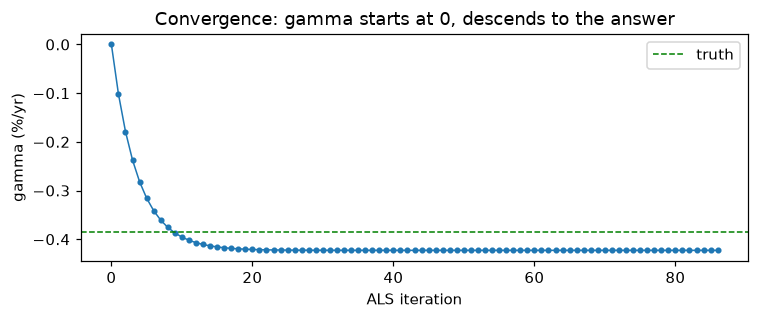

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(100*trace, 'o-', ms=3, lw=1)
ax.axhline(100*GAMMA_TRUE, color='g', lw=1, ls='--', label='truth')
ax.set_xlabel('ALS iteration'); ax.set_ylabel('gamma (%/yr)')
ax.set_title('Convergence: gamma starts at 0, descends to the answer')
ax.legend()
plt.tight_layout(); plt.show()

## 4. Cross-check against a general-purpose optimizer

`scipy.optimize.least_squares` minimizes the same sum of squared misses by guided descent, knowing nothing about the bilinear structure. Same bowl, different route, same bottom — a useful independence check on the ALS implementation.

In [5]:
sol = least_squares(lambda p: (p[0] + p[1]*g)*(1 + p[2]*t) - rho,
                    x0=[rho.mean(), 0.0, 0.0])
print("scipy  :", np.round(sol.x, 6))
print("ALS    :", np.round([alpha, beta, gamma], 6))
print("max |difference| :", np.max(np.abs(sol.x - [alpha, beta, gamma])))

scipy  : [ 0.441859  0.094185 -0.004231]
ALS    : [ 0.441859  0.094181 -0.004228]
max |difference| : 4.1454931284101715e-06


## 5. Seeing the decomposition

Line 3 says every observation is (site factor) x (drift curve). Divide each observation by its fitted site factor and the geometry scatter should vanish, leaving the bare normalized response $R(t)/R(0) = 1 + \gamma t$ — the quantity that equals 1 at t = 0 by construction and decays with drift.

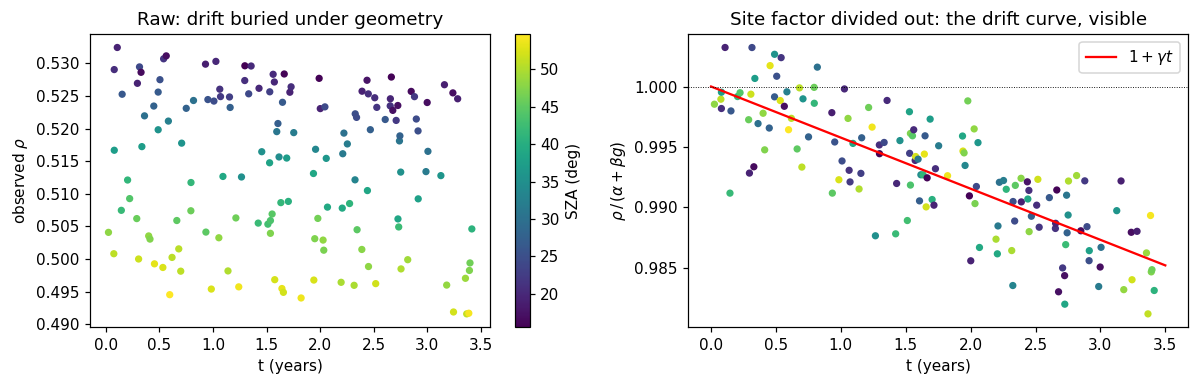

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)

sc = axes[0].scatter(t, rho, c=sza, cmap='viridis', s=14)
axes[0].set_xlabel('t (years)'); axes[0].set_ylabel(r'observed $\rho$')
axes[0].set_title('Raw: drift buried under geometry')
plt.colorbar(sc, ax=axes[0], label='SZA (deg)')

norm = rho / (alpha + beta*g)
axes[1].scatter(t, norm, c=sza, cmap='viridis', s=14)
tt = np.linspace(0, 3.5, 50)
axes[1].plot(tt, 1 + gamma*tt, 'r-', lw=1.5, label=r'$1+\gamma t$')
axes[1].axhline(1.0, color='k', lw=0.6, ls=':')
axes[1].set_xlabel('t (years)'); axes[1].set_ylabel(r'$\rho\,/\,(\alpha+\beta g)$')
axes[1].set_title('Site factor divided out: the drift curve, visible')
axes[1].legend()
plt.tight_layout(); plt.show()

The right panel is the payoff picture: color (geometry) no longer organizes the points, and the ~1.3% decline over 3.5 years — invisible on the left — is now the dominant structure.

## 6. Why this beats the four-parameter system: fit both, compare

Fit the old unconstrained MLR on the same data and compare the drift estimates and their bootstrap uncertainties.

In [6]:
def drift_4param(t, g, rho, g_ref=np.cos(np.radians(30.0))):
    X = np.column_stack([np.ones_like(t), t, g, g*t])
    c4, *_ = np.linalg.lstsq(X, rho, rcond=None)
    return (c4[1] + c4[3]*g_ref) / (c4[0] + c4[2]*g_ref)   # drift at ref geometry

B = 1000
boot3, boot4 = [], []
for _ in range(B):
    idx = rng.integers(0, N, N)
    ti, gi, ri = t[idx], g[idx], rho[idx]
    if np.ptp(ti) < 0.5 or np.ptp(gi) < 0.05:       # degenerate resample guard
        continue
    _, _, g3, _, _ = fit_als(ti, gi, ri)
    boot3.append(g3)
    boot4.append(drift_4param(ti, gi, ri))
boot3, boot4 = 100*np.array(boot3), 100*np.array(boot4)

print(f"resamples kept: {len(boot3)}/{B}")
print(f"{'system':>28} {'drift %/yr':>12} {'boot SE':>9} {'95% CI':>20}")
for name, bb in [('3-param (gamma direct)', boot3), ('4-param (assembled ratio)', boot4)]:
    ci = np.percentile(bb, [2.5, 97.5])
    print(f"{name:>28} {np.mean(bb):>+12.3f} {np.std(bb):>9.3f}"
          f"   [{ci[0]:+.3f}, {ci[1]:+.3f}]")
print(f"{'truth':>28} {100*GAMMA_TRUE:>+12.3f}")

resamples kept: 1000/1000
                      system   drift %/yr   boot SE               95% CI
      3-param (gamma direct)       -0.422     0.025   [-0.470, -0.374]
   4-param (assembled ratio)       -0.427     0.031   [-0.488, -0.364]
                       truth       -0.385


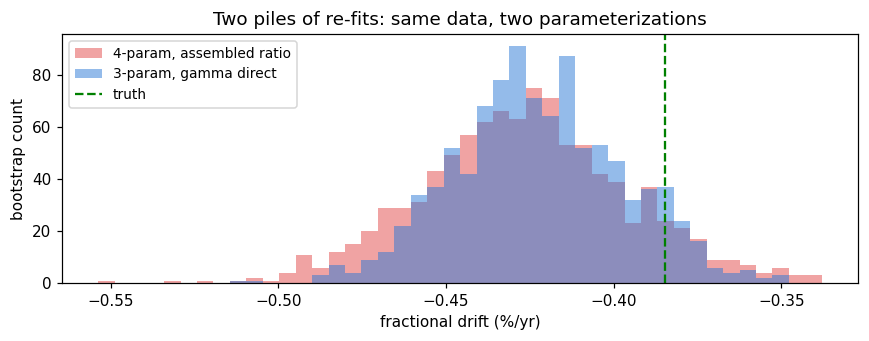

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(min(boot3.min(), boot4.min()), max(boot3.max(), boot4.max()), 45)
ax.hist(boot4, bins=bins, alpha=0.5, label='4-param, assembled ratio', color='#e34948')
ax.hist(boot3, bins=bins, alpha=0.5, label='3-param, gamma direct', color='#2a78d6')
ax.axvline(100*GAMMA_TRUE, color='g', lw=1.5, ls='--', label='truth')
ax.set_xlabel('fractional drift (%/yr)'); ax.set_ylabel('bootstrap count')
ax.set_title('Two piles of re-fits: same data, two parameterizations')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Both piles center near truth — the two systems estimate the same physical quantity, and at this noise level with well-separated sampling they perform comparably (the 4-param drift-at-reference-geometry combination was already the well-conditioned readout). The structural advantages of the 3-parameter form are elsewhere:

- $\gamma$ needs no assembly: no reference-geometry convention to fix, nothing to reconcile across runs.
- The multiplicative structure is enforced, not merely checked — there is no spare $\eta$ direction for noise (or real structure) to leak into, and no $\alpha\eta = \beta\gamma$ bookkeeping.
- Site pooling becomes natural: with multiple sites, each contributes its own $(\alpha_x, \beta_x)$ half-step while all scenes jointly update the one shared $\gamma_\lambda$ — the ALS loop extends to this with a few extra lines, which is the production path for the real archive.

## 7. What changed and what didn't

Changed: three parameters, direct $\gamma$, bilinear form, ALS (or scipy) instead of one `lstsq` call, symbols reassigned (old $\gamma$ geometry slope is now $\beta$; old $\beta$ is gone; $\gamma$ now means fractional drift).

Unchanged: the physics (line 2 is the same product), the scene-level bootstrap (wraps ALS exactly as it wrapped `lstsq`), the diagnostics (residuals vs t, g, VZA; corr(t, SZA); Theil-Sen canary on the marginal fits), and every reportable ratio ($\beta/\alpha$ here equals d/c, the directional sensitivity, matching the old $\gamma/\alpha$).